# 03 — Preprocessing & Augmentation

**Đầu vào:** ảnh hoa `images/roseflower.jpeg` (RGB, 270 × 270), mẫu dùng trong tài liệu Chương 4.

Notebook tái lập resize ảnh hoa xuống 50 × 50 của notebook gốc, so sánh ba nội suy, rồi minh họa ép tỷ lệ, giữ tỷ lệ có padding và crop. Chuẩn hóa và augmentation cũng dùng ảnh mẫu này. Notebook lưu hình kết quả vào `outputs/tu/` và có thể chạy từ thư mục gốc repository hoặc thư mục `notebooks`.

Ví dụ tập trung vào xử lý ảnh trong Chương 4; không tải CIFAR-10 hoặc ghi đè ảnh nguồn.


## 1. Thư viện và dữ liệu đầu vào

- **Đầu vào:** `images/roseflower.jpeg`, ảnh hoa mẫu dùng trong notebook Chương 4.
- **NumPy/OpenCV:** biểu diễn ảnh, resize, crop và augmentation.
- **Matplotlib:** trực quan hóa và lưu hình.

Notebook tìm repository từ thư mục làm việc hiện tại hoặc thư mục cha, nên có thể chạy từ gốc repo hoặc `notebooks/`. Ảnh đầu vào và thư mục lưu hình được xác định theo repository, không phụ thuộc thư mục kernel.


In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

working_directory = Path.cwd().resolve()
search_roots = [working_directory, *working_directory.parents]
repository_root = next(
(
        parent
        for parent in search_roots
        if (parent / "images" / "roseflower.jpeg").is_file()
        and (parent / "notebooks").is_dir()
    ),
    None,
)
if repository_root is None:
    checked_roots = "\n".join(str(parent) for parent in search_roots)
    raise FileNotFoundError(
        "Không tìm thấy thư mục repository có images/roseflower.jpeg và notebooks/. "
        f"Các thư mục đã kiểm tra:\n{checked_roots}"
    )

SAMPLE_IMAGE_PATH = repository_root / "images" / "roseflower.jpeg"
OUTPUT_DIR = repository_root / "outputs" / "tu"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"NumPy: {np.__version__}")
print(f"OpenCV: {cv2.__version__}")
print(f"Ảnh mẫu: {SAMPLE_IMAGE_PATH}")
print(f"Thư mục lưu hình: {OUTPUT_DIR}")


NumPy: 2.3.5
OpenCV: 5.0.0
Ảnh mẫu: D:\KH1-Y4\PR_Seminar_BaKhi\images\roseflower.jpeg
Thư mục lưu hình: D:\KH1-Y4\PR_Seminar_BaKhi\outputs\tu


In [2]:
original_bgr = cv2.imread(str(SAMPLE_IMAGE_PATH), cv2.IMREAD_COLOR)
if original_bgr is None:
    raise OSError(f"Tìm thấy nhưng không đọc được ảnh mẫu: {SAMPLE_IMAGE_PATH}")
original_image = cv2.cvtColor(original_bgr, cv2.COLOR_BGR2RGB)
image_height, image_width = original_image.shape[:2]
print(f"Shape: {original_image.shape}; dtype: {original_image.dtype}")
print(f"Pixel range: {original_image.min()}–{original_image.max()}")

Shape: (270, 270, 3); dtype: uint8
Pixel range: 0–255


## 2. Resize, nội suy và tỷ lệ khung hình

**Mục đích:** Đưa ảnh về kích thước đầu vào thống nhất để dễ tạo batch và so sánh; giảm số pixel cũng giảm bộ nhớ và phép tính ở các bước sau. Ảnh mẫu 270 × 270 có 72.900 pixel, còn ảnh 50 × 50 có 2.500 pixel (ít hơn khoảng 29 lần).

**Lý do áp dụng:** Mô hình và phép xử lý theo lô thường cần ảnh cùng chiều cao, chiều rộng. Giảm kích thước giúp xử lý nhanh hơn, nhưng đánh đổi độ chi tiết; nội suy quyết định cách tính giá trị pixel mới khi đổi kích thước.

**Lợi ích và đánh đổi:** Kích thước đầu ra đồng nhất giúp dữ liệu tương thích với đầu vào cố định và giảm chi phí tính toán. `INTER_NEAREST`, `INTER_AREA` và `INTER_CUBIC` cho cách tổng hợp pixel khác nhau; không cách nào khôi phục chi tiết đã mất khi thu nhỏ.

**Kết quả:** Hàng trên so sánh ba phương pháp nội suy khi thu ảnh về 50 × 50. Hàng dưới đưa ảnh vuông vào canvas 224 × 160: ép trực tiếp làm méo tỷ lệ, padding giữ nguyên hình dạng nhưng thêm viền, còn crop lấp đầy canvas nhưng có thể cắt nội dung.

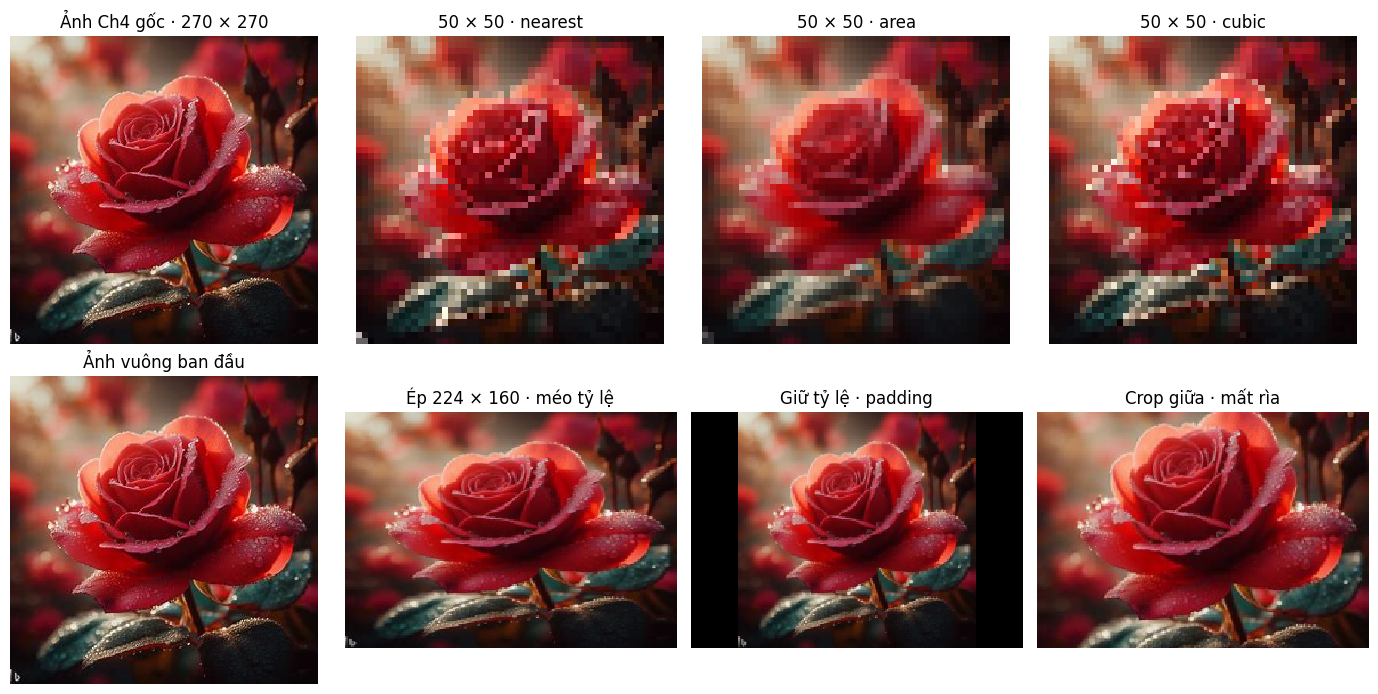

Đã lưu: D:\KH1-Y4\PR_Seminar_BaKhi\outputs\tu\01_resize_comparison.png
Shape ảnh giảm kích thước: (50, 50, 3)
Shape ảnh theo canvas: (160, 224, 3)


In [3]:
def resize_with_aspect_ratio_and_padding(image: np.ndarray, target_size: tuple[int, int]) -> np.ndarray:
    """Resize proportionally and center the result on a black RGB canvas."""
    target_width, target_height = target_size
    source_height, source_width = image.shape[:2]
    scale = min(target_width / source_width, target_height / source_height)
    resized_width = max(1, round(source_width * scale))
    resized_height = max(1, round(source_height * scale))
    interpolation = cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR
    resized_image = cv2.resize(image, (resized_width, resized_height), interpolation=interpolation)
    canvas = np.zeros((target_height, target_width, 3), dtype=np.uint8)
    offset_x = (target_width - resized_width) // 2
    offset_y = (target_height - resized_height) // 2
    canvas[offset_y:offset_y + resized_height, offset_x:offset_x + resized_width] = resized_image
    return canvas


def center_crop_and_resize(image: np.ndarray, target_size: tuple[int, int]) -> np.ndarray:
    """Center-crop to the target aspect ratio, then resize to the target size."""
    target_width, target_height = target_size
    source_height, source_width = image.shape[:2]
    target_ratio = target_width / target_height
    source_ratio = source_width / source_height
    if source_ratio > target_ratio:
        cropped_width = round(source_height * target_ratio)
        left = (source_width - cropped_width) // 2
        cropped_image = image[:, left:left + cropped_width]
    else:
        cropped_height = round(source_width / target_ratio)
        top = (source_height - cropped_height) // 2
        cropped_image = image[top:top + cropped_height, :]
    return cv2.resize(cropped_image, target_size, interpolation=cv2.INTER_AREA)


small_size = (50, 50)
nearest_image = cv2.resize(original_image, small_size, interpolation=cv2.INTER_NEAREST)
area_image = cv2.resize(original_image, small_size, interpolation=cv2.INTER_AREA)
cubic_image = cv2.resize(original_image, small_size, interpolation=cv2.INTER_CUBIC)
target_size = (224, 160)
stretched_image = cv2.resize(original_image, target_size, interpolation=cv2.INTER_AREA)
padded_image = resize_with_aspect_ratio_and_padding(original_image, target_size)
cropped_image = center_crop_and_resize(original_image, target_size)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
small_examples = [
    (original_image, f"Ảnh Ch4 gốc · {image_width} × {image_height}"),
    (nearest_image, "50 × 50 · nearest"),
    (area_image, "50 × 50 · area"),
    (cubic_image, "50 × 50 · cubic"),
]
for axis, (image, title) in zip(axes[0], small_examples):
    axis.imshow(image, interpolation="nearest")
    axis.set_title(title)
    axis.axis("off")
aspect_examples = [
    (original_image, "Ảnh vuông ban đầu"),
    (stretched_image, "Ép 224 × 160 · méo tỷ lệ"),
    (padded_image, "Giữ tỷ lệ · padding"),
    (cropped_image, "Crop giữa · mất rìa"),
]
for axis, (image, title) in zip(axes[1], aspect_examples):
    axis.imshow(image, interpolation="nearest")
    axis.set_title(title)
    axis.axis("off")
fig.tight_layout()
resize_figure_path = OUTPUT_DIR / "01_resize_comparison.png"
fig.savefig(resize_figure_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Đã lưu: {resize_figure_path}")
print(f"Shape ảnh giảm kích thước: {nearest_image.shape}")
print(f"Shape ảnh theo canvas: {stretched_image.shape}")

**Nhận xét:** `nearest`, `area` và `cubic` tạo kết quả khác nhau khi thu ảnh về 50 × 50, nhưng không khôi phục chi tiết đã mất do giảm độ phân giải. Với canvas 224 × 160, ép trực tiếp làm hoa bị dẹt theo chiều dọc; giữ tỷ lệ thêm vùng đen hai bên; crop lấp đầy canvas nhưng cắt bớt phần trên/dưới. Cùng shape tensor không đồng nghĩa cùng nội dung hình ảnh.

## 3. Chuẩn hóa giá trị pixel

**Mục đích:** Đưa cường độ pixel từ `uint8` 0–255 về `float32` trong khoảng 0–1 bằng phép chia cho 255.

**Lý do áp dụng:** Các giá trị đầu vào cùng thang đo giúp tránh việc độ lớn số pixel chi phối không cần thiết các phép tính; nhiều mô hình và thư viện cũng mong đợi ảnh số thực trong khoảng 0–1. Chuẩn hóa nhất quán ở lúc huấn luyện và suy luận là điều kiện quan trọng.

**Lợi ích và giới hạn:** Miền giá trị nhỏ, thống nhất thường giúp tính toán và tối ưu ổn định hơn, nhưng không bảo đảm mô hình tốt hơn trong mọi bài toán và không làm ảnh chứa thêm thông tin. Đây là chuẩn hóa min-max theo miền pixel, khác với z-score `(x - mean) / std`.

**Kết quả:** Hình so sánh ảnh màu gốc, kênh đỏ sau chuẩn hóa và ảnh đổi ngược về `uint8`; các giá trị min/max được in ra để kiểm tra miền `[0, 1]`. Ảnh đổi ngược giống ảnh đầu vào trong phép kiểm tra bên dưới.

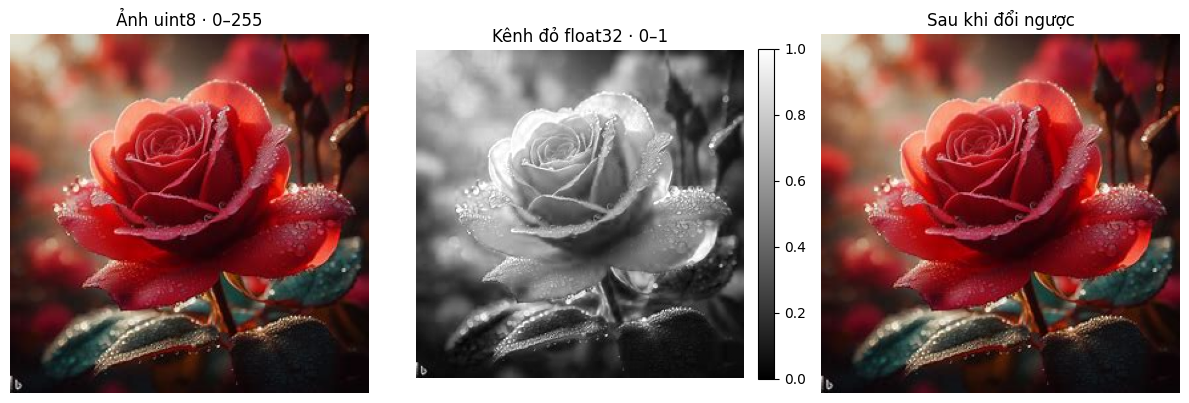

Trước: dtype=uint8, range=[0, 255]
Sau: dtype=float32, range=[0.000, 1.000]
Sai số tuyệt đối lớn nhất sau đổi ngược: 0
Đã lưu: D:\KH1-Y4\PR_Seminar_BaKhi\outputs\tu\02_normalization.png


In [4]:
normalized_image = original_image.astype(np.float32) / 255.0
restored_image = np.clip(normalized_image * 255.0, 0, 255).round().astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(original_image)
axes[0].set_title("Ảnh uint8 · 0–255")
axes[0].axis("off")

normalized_channel = axes[1].imshow(
    normalized_image[:, :, 0],
    cmap="gray",
    vmin=0,
    vmax=1,
)
axes[1].set_title("Kênh đỏ float32 · 0–1")
axes[1].axis("off")
fig.colorbar(normalized_channel, ax=axes[1], fraction=0.046, pad=0.04)

axes[2].imshow(restored_image)
axes[2].set_title("Sau khi đổi ngược")
axes[2].axis("off")
fig.tight_layout()
normalization_figure_path = OUTPUT_DIR / "02_normalization.png"
fig.savefig(normalization_figure_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

print(
    f"Trước: dtype={original_image.dtype}, range="
    f"[{original_image.min()}, {original_image.max()}]"
)
print(
    f"Sau: dtype={normalized_image.dtype}, range="
    f"[{normalized_image.min():.3f}, {normalized_image.max():.3f}]"
)
print(f"Sai số tuyệt đối lớn nhất sau đổi ngược: {np.abs(original_image.astype(np.int16) - restored_image.astype(np.int16)).max()}")
print(f"Đã lưu: {normalization_figure_path}")

## 4. Augmentation hình học

**Mục đích:** Tạo các biến thể hình học từ ảnh huấn luyện để mô phỏng một phần thay đổi có thể gặp ở ảnh mới.

**Lý do áp dụng:** Khi tập huấn luyện còn hạn chế, lật, xoay, tịnh tiến, shear và zoom có thể giúp mô hình không chỉ ghi nhớ đúng vị trí hoặc tư thế xuất hiện trong một số ít ảnh.

**Lợi ích và giới hạn:** Những biến thể hợp lệ có thể tăng đa dạng dữ liệu huấn luyện và hỗ trợ khả năng tổng quát hóa; chúng không thay thế dữ liệu mới độc lập. Chỉ áp dụng biến đổi vẫn giữ ý nghĩa nhãn: xoay/tịnh tiến/shear có thể tạo vùng biên đen, còn zoom có thể cắt chi tiết ở rìa.

**Kết quả:** Hình minh họa đặt ảnh hoa Ch4 cạnh các ảnh sau từng phép biến đổi để quan sát thay đổi hình dạng và vùng bị thêm/cắt. Cell này minh họa phép biến đổi, không phải đánh giá định lượng chất lượng mô hình.

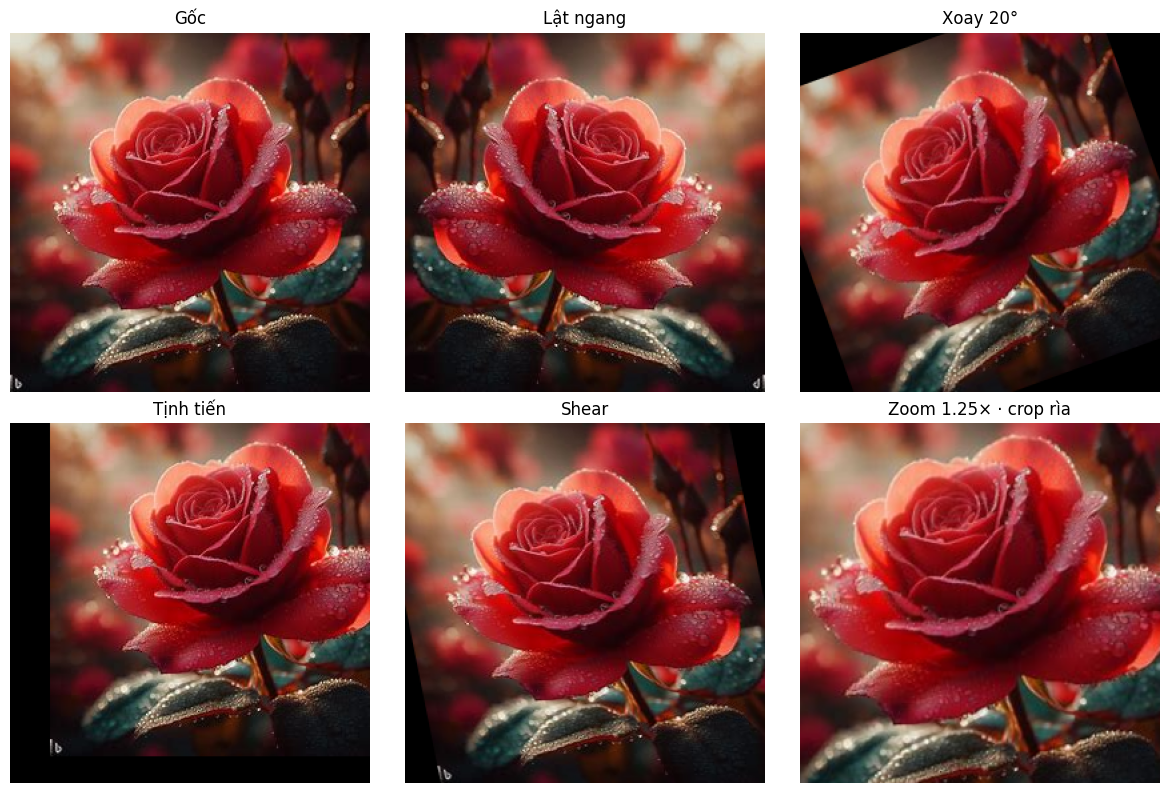

Đã lưu: D:\KH1-Y4\PR_Seminar_BaKhi\outputs\tu\03_augmentation_examples.png


In [5]:
source_height, source_width = original_image.shape[:2]
center_x, center_y = source_width / 2, source_height / 2
flipped_image = cv2.flip(original_image, 1)
rotation_matrix = cv2.getRotationMatrix2D((center_x, center_y), 20, 1.0)
rotated_image = cv2.warpAffine(original_image, rotation_matrix, (source_width, source_height), borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0))
translation_matrix = np.float32([[1, 0, 30], [0, 1, -20]])
translated_image = cv2.warpAffine(original_image, translation_matrix, (source_width, source_height), borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0))
shear_matrix = np.float32([[1, 0.2, -0.1 * source_height], [0, 1, 0]])
sheared_image = cv2.warpAffine(original_image, shear_matrix, (source_width, source_height), borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0))
zoom_matrix = cv2.getRotationMatrix2D((center_x, center_y), 0, 1.25)
zoomed_image = cv2.warpAffine(original_image, zoom_matrix, (source_width, source_height), borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0))

augmentation_examples = [
    (original_image, "Gốc"), (flipped_image, "Lật ngang"),
    (rotated_image, "Xoay 20°"), (translated_image, "Tịnh tiến"),
    (sheared_image, "Shear"), (zoomed_image, "Zoom 1.25× · crop rìa"),
]
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for axis, (image, title) in zip(axes.flat, augmentation_examples):
    axis.imshow(image)
    axis.set_title(title)
    axis.axis("off")
fig.tight_layout()
augmentation_figure_path = OUTPUT_DIR / "03_augmentation_examples.png"
fig.savefig(augmentation_figure_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Đã lưu: {augmentation_figure_path}")

## 5. Kiểm tra kết quả

Các cell dùng ảnh mẫu có sẵn trong repository, không tải dữ liệu mạng và không ghi đè ảnh gốc. Các kiểm tra dưới đây xác nhận shape, miền pixel, phép đổi ngược và các file kết quả.

In [6]:
assert nearest_image.shape == (50, 50, 3)
assert area_image.shape == (50, 50, 3)
assert cubic_image.shape == (50, 50, 3)
assert stretched_image.shape == (160, 224, 3)
assert padded_image.shape == (160, 224, 3)
assert cropped_image.shape == (160, 224, 3)
assert normalized_image.dtype == np.float32
assert 0.0 <= float(normalized_image.min()) <= float(normalized_image.max()) <= 1.0
assert np.array_equal(original_image, restored_image)
saved_figures = [resize_figure_path, normalization_figure_path, augmentation_figure_path]
for figure_path in saved_figures:
    assert figure_path.is_file(), f"Chưa tạo được hình: {figure_path}"
    assert figure_path.stat().st_size > 0, f"Hình rỗng: {figure_path}"
    print(f"OK · {figure_path} · {figure_path.stat().st_size:,} bytes")
print("Tất cả kiểm tra đều đạt.")

OK · D:\KH1-Y4\PR_Seminar_BaKhi\outputs\tu\01_resize_comparison.png · 714,796 bytes
OK · D:\KH1-Y4\PR_Seminar_BaKhi\outputs\tu\02_normalization.png · 641,402 bytes
OK · D:\KH1-Y4\PR_Seminar_BaKhi\outputs\tu\03_augmentation_examples.png · 1,615,945 bytes
Tất cả kiểm tra đều đạt.


### Nhận xét kết quả

- Thu ảnh mẫu Ch4 từ 270 × 270 xuống 50 × 50 làm giảm đáng kể số pixel; nội suy khác nhau về cách tổng hợp pixel nhưng không khôi phục chi tiết gốc.
- Ép ảnh vuông sang canvas chữ nhật làm thay đổi hình dạng; padding giữ tỷ lệ nhưng thêm nền, còn crop có thể loại bỏ nội dung ở biên.
- `uint8 / 255` đưa pixel về `[0, 1]`; huấn luyện và suy luận cần dùng cùng quy ước chuẩn hóa.
- Lật, xoay, tịnh tiến, shear và zoom mở rộng biến thiên dữ liệu, nhưng có thể làm mất rìa hoặc thay đổi đặc trưng/ý nghĩa nhãn nếu áp dụng quá mức.

Ba hình được tạo từ `images/roseflower.jpeg` và lưu tại `outputs/tu/`.
